# BRCA ST patient B — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **B**: patient 10737, sections B1–B6, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=B bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
)

PATIENT = "B"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


B  n=6
BT10737_C1_HE  mpp=0.6913 µm/px  native16=11.06 µm  after rescale=8.0 µm  scale=1.3827  (ST 200 µm spot pitch (B1))
  pred exists: True
BT10737_C2_HE  mpp=0.6898 µm/px  native16=11.04 µm  after rescale=8.0 µm  scale=1.3795  (ST 200 µm spot pitch (B2))
  pred exists: True
BT10737_D1_HE  mpp=0.6894 µm/px  native16=11.03 µm  after rescale=8.0 µm  scale=1.3788  (ST 200 µm spot pitch (B3))
  pred exists: True
BT10737_D2_HE  mpp=0.6887 µm/px  native16=11.02 µm  after rescale=8.0 µm  scale=1.3773  (ST 200 µm spot pitch (B4))
  pred exists: True
BT10737_E1_HE  mpp=0.6894 µm/px  native16=11.03 µm  after rescale=8.0 µm  scale=1.3789  (ST 200 µm spot pitch (B5))
  pred exists: True
BT10737_E2_HE  mpp=0.6902 µm/px  native16=11.04 µm  after rescale=8.0 µm  scale=1.3804  (ST 200 µm spot pitch (B6))
  pred exists: True


## B — composition and spatial labels


===== B L1 =====


fraction                                            \
sample      BT10737_C1_HE BT10737_C2_HE BT10737_D1_HE BT10737_D2_HE   
class                                                                 
Immune              0.516         0.562         0.530         0.489   
Endothelial         0.354         0.228         0.335         0.368   
Stromal             0.083         0.201         0.118         0.128   
Epithelial          0.048         0.009         0.016         0.015   
Neural                NaN           NaN           NaN         0.000   

                                            mean_conf                \
sample      BT10737_E1_HE BT10737_E2_HE BT10737_C1_HE BT10737_C2_HE   
class                                                                 
Immune              0.485         0.518         0.637         0.633   
Endothelial         0.395         0.366         0.479         0.494   
Stromal             0.107         0.109         0.439         0.485   
Epithelial          0.013         0.006         0.463         0.479   
Neural                NaN           NaN           NaN           NaN   

                                                                     \
sample      BT10737_D1_HE BT10737_D2_HE BT10737_E1_HE BT10737_E2_HE   
class                                                                 
Immune              0.634         0.656         0.647         0.654   
Endothelial         0.495         0.511         0.507         0.529   
Stromal             0.450         0.468         0.456         0.455   
Epithelial          0.452         0.456         0.442         0.465   
Neural                NaN         0.348           NaN           NaN   

                        n                                            \
sample      BT10737_C1_HE BT10737_C2_HE BT10737_D1_HE BT10737_D2_HE   
class                                                                 
Immune            18596.0       16772.0       16955.0       14974.0   
Endothelial       12740.0        6812.0       10730.0       11248.0   
Stromal            2974.0        6008.0        3785.0        3905.0   
Epithelial         1715.0         256.0         521.0         474.0   
Neural                NaN           NaN           NaN           1.0   

                                         
sample      BT10737_E1_HE BT10737_E2_HE  
class                                    
Immune            14970.0       15264.0  
Endothelial       12202.0       10784.0  
Stromal            3288.0        3209.0  
Epithelial          409.0         182.0  
Neural                NaN           NaN

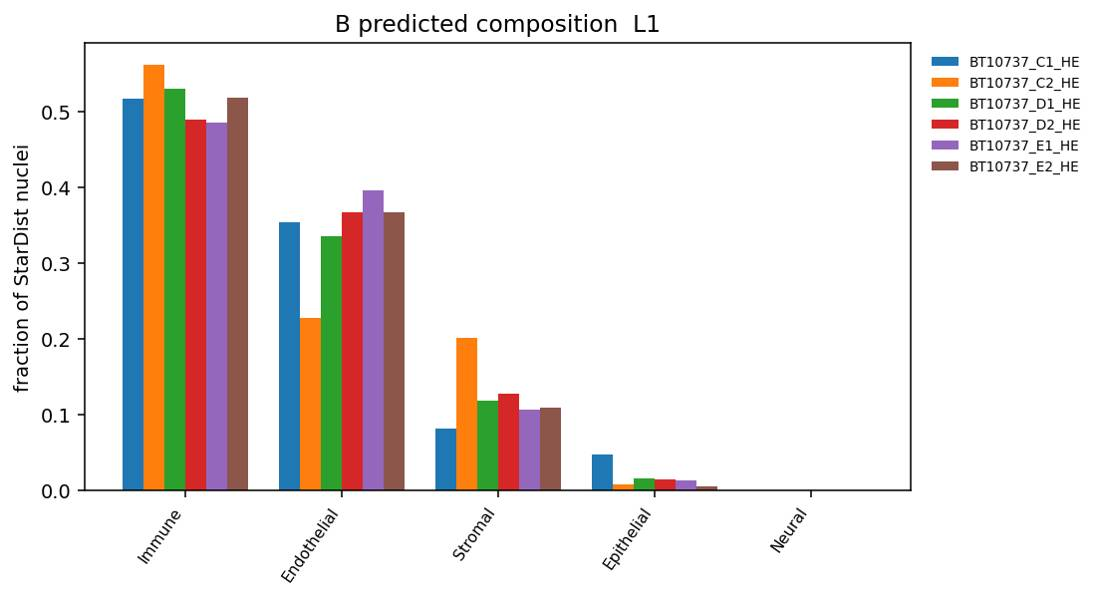

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/B_composition_L1.png

===== B L12 =====


fraction                                            \
sample      BT10737_C1_HE BT10737_C2_HE BT10737_D1_HE BT10737_D2_HE   
class                                                                 
T_cell              0.604         0.663         0.631         0.580   
Stromal             0.168         0.238         0.209         0.243   
Endothelial         0.084         0.048         0.089         0.108   
Myeloid             0.050         0.026         0.043         0.029   
B_Plasma            0.045         0.018         0.015         0.023   
Epithelial          0.043         0.004         0.011         0.013   
Tumor               0.006         0.004         0.004         0.004   

                                            mean_conf                \
sample      BT10737_E1_HE BT10737_E2_HE BT10737_C1_HE BT10737_C2_HE   
class                                                                 
T_cell              0.595         0.617         0.472         0.522   
Stromal             0.239         0.215         0.356         0.399   
Endothelial         0.105         0.114         0.320         0.342   
Myeloid             0.035         0.027         0.304         0.317   
B_Plasma            0.011         0.020         0.436         0.435   
Epithelial          0.009         0.005         0.390         0.347   
Tumor               0.005         0.002         0.370         0.401   

                                                                     \
sample      BT10737_D1_HE BT10737_D2_HE BT10737_E1_HE BT10737_E2_HE   
class                                                                 
T_cell              0.511         0.513         0.515         0.528   
Stromal             0.374         0.389         0.384         0.382   
Endothelial         0.337         0.340         0.340         0.366   
Myeloid             0.306         0.311         0.312         0.323   
B_Plasma            0.417         0.438         0.410         0.422   
Epithelial          0.371         0.364         0.355         0.378   
Tumor               0.353         0.389         0.367         0.379   

                        n                                            \
sample      BT10737_C1_HE BT10737_C2_HE BT10737_D1_HE BT10737_D2_HE   
class                                                                 
T_cell            21772.0       19778.0       20201.0       17759.0   
Stromal            6047.0        7098.0        6675.0        7448.0   
Endothelial        3015.0        1423.0        2834.0        3293.0   
Myeloid            1789.0         789.0        1360.0         880.0   
B_Plasma           1608.0         533.0         466.0         708.0   
Epithelial         1562.0         122.0         337.0         406.0   
Tumor               232.0         105.0         118.0         108.0   

                                         
sample      BT10737_E1_HE BT10737_E2_HE  
class                                    
T_cell            18361.0       18172.0  
Stromal            7387.0        6339.0  
Endothelial        3256.0        3355.0  
Myeloid            1088.0         789.0  
B_Plasma            349.0         592.0  
Epithelial          288.0         145.0  
Tumor               140.0          47.0

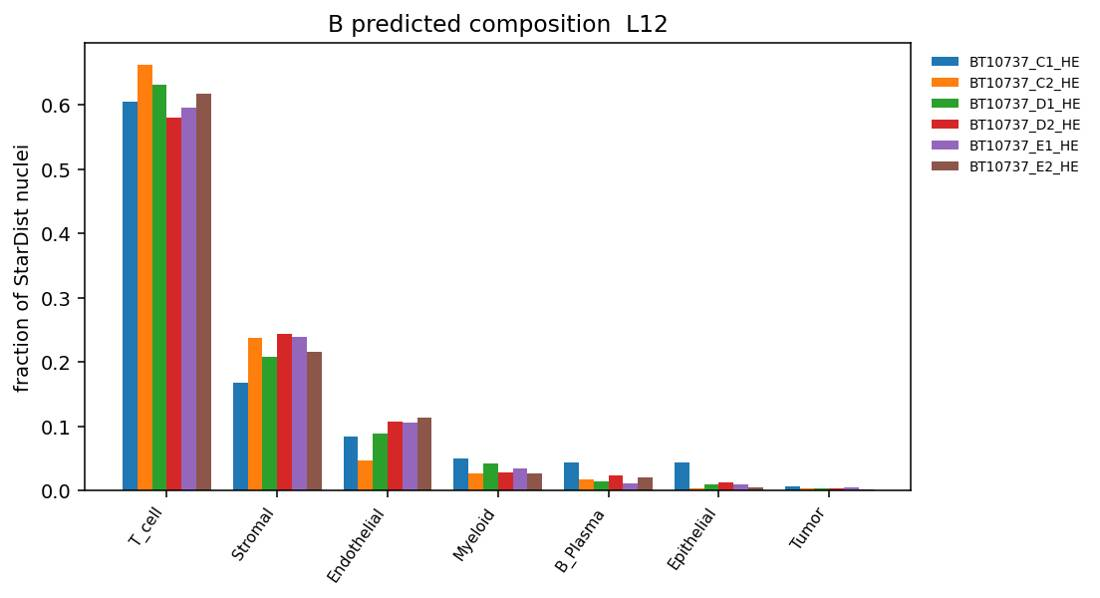

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/B_composition_L12.png

===== B L2 =====


fraction                                            \
sample            BT10737_C1_HE BT10737_C2_HE BT10737_D1_HE BT10737_D2_HE   
class                                                                       
B_cell                    0.431         0.391         0.375         0.386   
Endothelial               0.247         0.145         0.246         0.285   
Fibroblast                0.080         0.208         0.097         0.078   
CD4_T                     0.126         0.183         0.176         0.130   
Stromal                   0.026         0.023         0.037         0.055   
CD8_T                     0.018         0.015         0.027         0.023   
Plasma                    0.013         0.005         0.010         0.017   
Injury_epithelial         0.017         0.001         0.005         0.004   
Epithelial                0.017         0.002         0.005         0.006   
Neutrophil                0.013         0.014         0.014         0.008   
Tumor                     0.008         0.003         0.005         0.004   
Tregs                     0.000         0.006         0.000         0.000   
DCIS                      0.001         0.002         0.000           NaN   
DC                        0.002         0.001         0.001         0.000   
Myofibroblast             0.000         0.001         0.001         0.001   
Macrophage                0.000         0.000         0.001         0.001   
NK                        0.000         0.000         0.000         0.000   
Alveolar                  0.000           NaN         0.000         0.000   
Myoepithelial             0.000         0.000           NaN         0.000   
Neural                      NaN           NaN           NaN         0.000   

                                                  mean_conf                \
sample            BT10737_E1_HE BT10737_E2_HE BT10737_C1_HE BT10737_C2_HE   
class                                                                       
B_cell                    0.335         0.366         0.435         0.413   
Endothelial               0.301         0.270         0.260         0.285   
Fibroblast                0.077         0.100         0.238         0.297   
CD4_T                     0.169         0.172         0.294         0.329   
Stromal                   0.042         0.025         0.315         0.336   
CD8_T                     0.034         0.037         0.242         0.272   
Plasma                    0.014         0.012         0.247         0.281   
Injury_epithelial         0.004         0.003         0.274         0.236   
Epithelial                0.004         0.002         0.252         0.280   
Neutrophil                0.010         0.006         0.218         0.253   
Tumor                     0.006         0.002         0.307         0.326   
Tregs                     0.000         0.001         0.244         0.259   
DCIS                        NaN           NaN         0.358         0.424   
DC                        0.001         0.000         0.270         0.240   
Myofibroblast             0.001         0.002         0.210         0.235   
Macrophage                0.001         0.002         0.149         0.165   
NK                        0.000         0.000         0.129         0.198   
Alveolar                  0.000           NaN         0.173           NaN   
Myoepithelial             0.000         0.000         0.194         0.272   
Neural                      NaN           NaN           NaN           NaN   

                                                                           \
sample            BT10737_D1_HE BT10737_D2_HE BT10737_E1_HE BT10737_E2_HE   
class                                                                       
B_cell                    0.396         0.432         0.390         0.403   
Endothelial               0.278         0.289         0.285         0.313   
Fibroblast                0.243         0.249         0.244         0.263   
CD4_T            

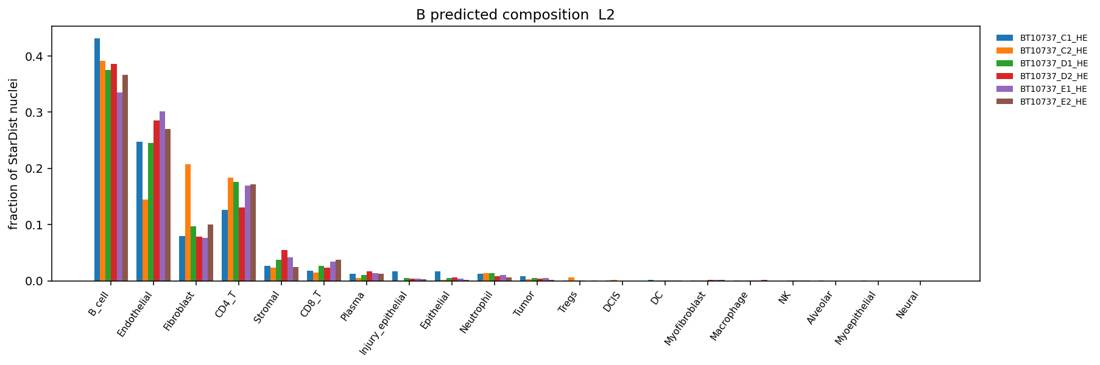

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/B_composition_L2.png
BT10737_C1_HE


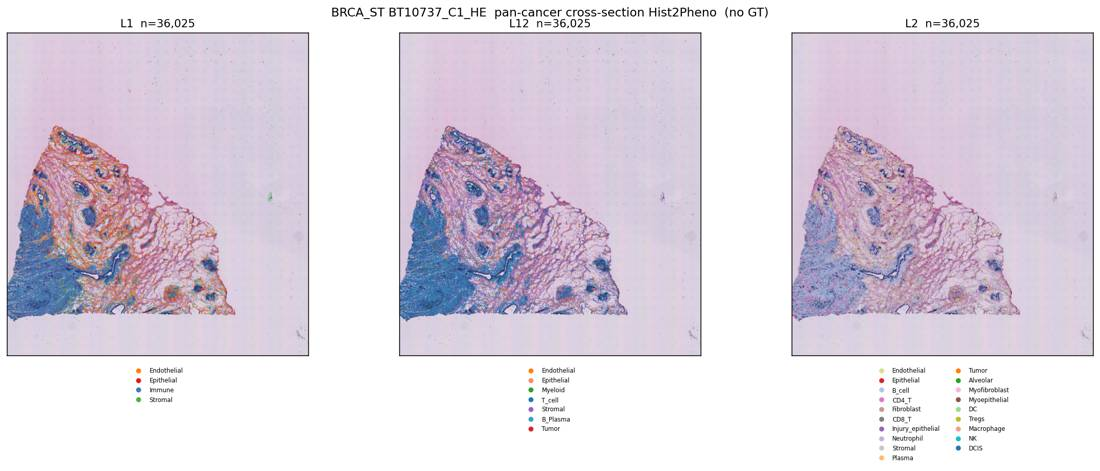

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C1_HE_spatial_L1_L12_L2.png
BT10737_C2_HE


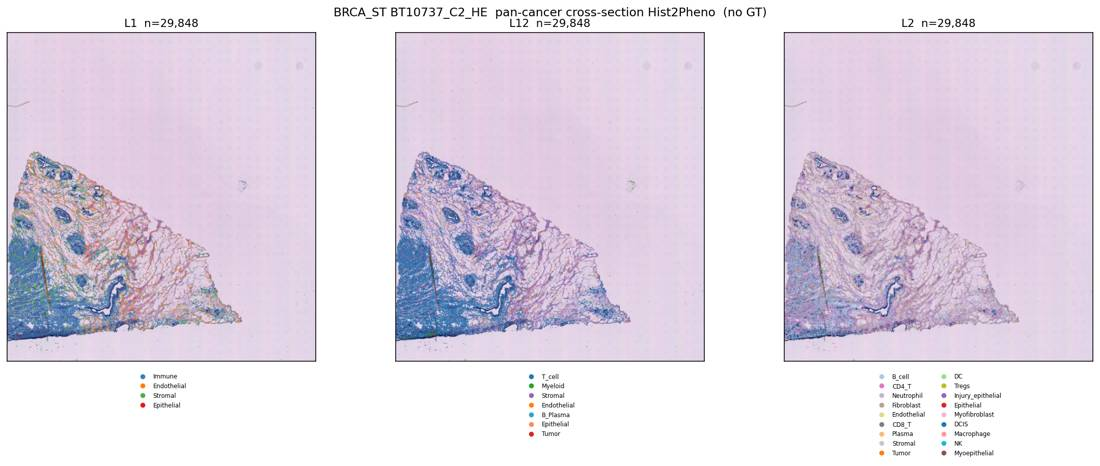

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C2_HE_spatial_L1_L12_L2.png
BT10737_D1_HE


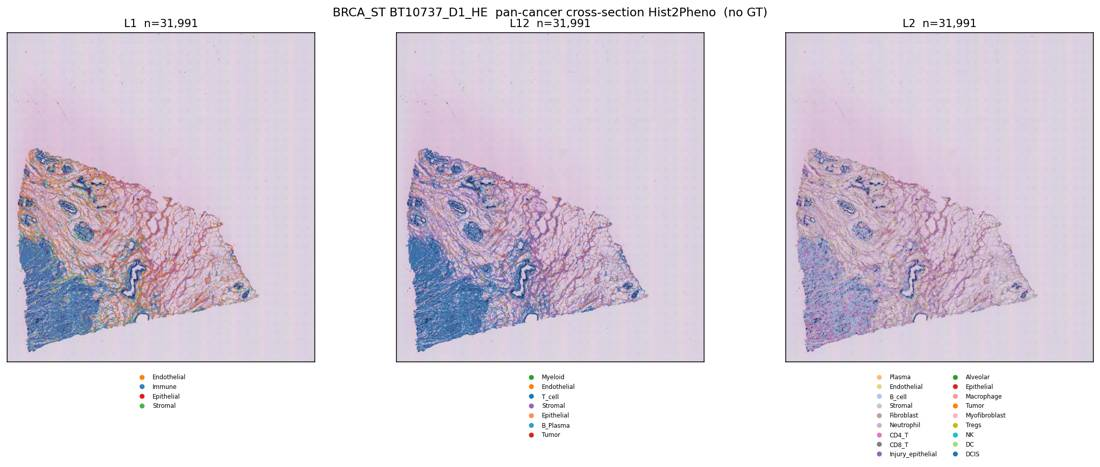

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D1_HE_spatial_L1_L12_L2.png
BT10737_D2_HE


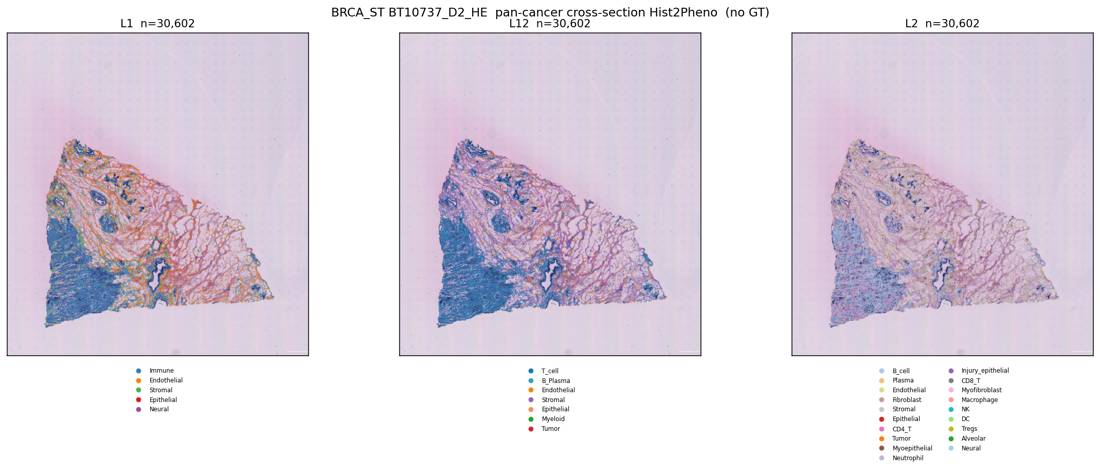

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D2_HE_spatial_L1_L12_L2.png
BT10737_E1_HE


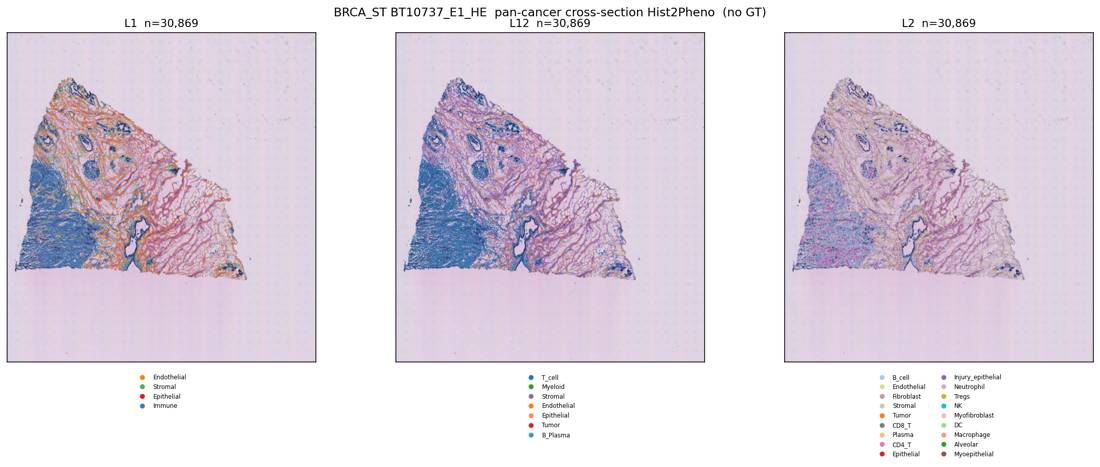

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E1_HE_spatial_L1_L12_L2.png
BT10737_E2_HE


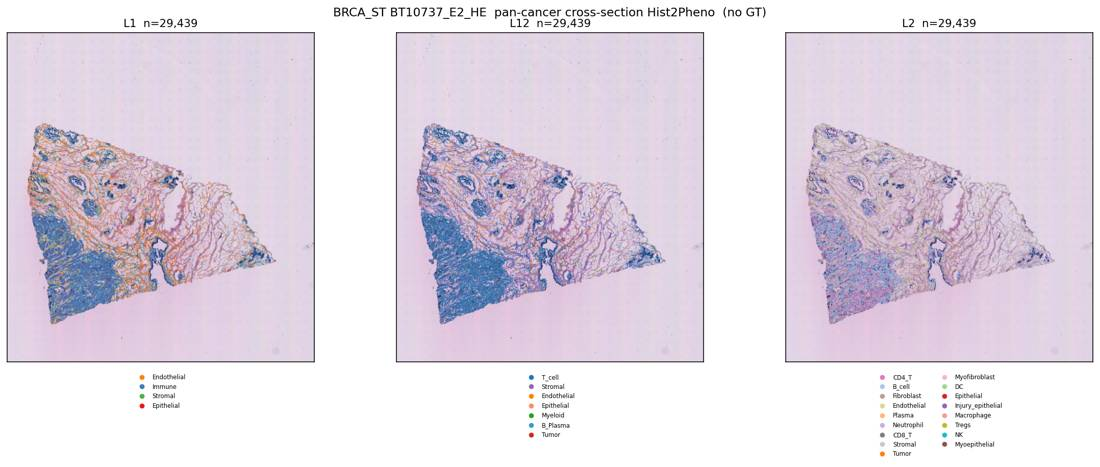

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E2_HE_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    if SAVE_FIGURES:
        out = fig_dir / f"{PATIENT}_composition_{head}.png"
        fig.savefig(out, dpi=DPI, bbox_inches="tight")
        print(out)
    display(fig)
    plt.close(fig)

for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## B — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/BT10737_C1_HE/BT10737_C1_HE_l2_probs.npz  (36025, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/BT10737_C1_HE/BT10737_C1_HE_niche_indices.h5ad  n=36,025
  TLS hotspot: {'n_cells_total': 36025, 'n_candidate_cells': 1802, 'fraction_candidate': 0.050020818875780707, 'max_tls_spatial': 0.2701979729655696, 'mean_tls_spatial_candidate': 0.2191102656357656, 'centroid_x': 857.5117790988387, 'centroid_y': 7620.941399899228}
  mean TLS=0.561  TLS_spatial=0.137  SRI=7.940  TNI=14.926
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/BT10737_C2_HE/BT10737_C2_HE_l2_probs.npz  (29848, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/BT10737_C2_HE/BT10737_C2_HE_niche_indices.h5ad  n=29,848
  TLS hotspot: {'n_cells_total': 29848, 'n_candidate_cells': 1493, 'fraction_candidat

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,BT10737_C1_HE,36025,0.561,0.568,0.937,0.990,0.137,0.140,0.207,0.270,0.827,0.811,0.046,0.088,0.184,0.832
1,BT10737_C2_HE,29848,0.585,0.615,0.939,0.989,0.137,0.148,0.189,0.236,0.763,0.738,0.050,0.094,0.171,0.802
2,BT10737_D1_HE,31991,0.563,0.589,0.932,0.990,0.132,0.138,0.195,0.256,0.841,0.820,0.053,0.100,0.179,0.824
3,BT10737_D2_HE,30602,0.546,0.551,0.947,0.988,0.123,0.123,0.191,0.235,0.852,0.837,0.080,0.148,0.177,0.866
4,BT10737_E1_HE,30869,0.539,0.543,0.932,0.988,0.125,0.122,0.199,0.248,0.858,0.840,0.067,0.125,0.184,0.840
5,BT10737_E2_HE,29439,0.565,0.594,0.943,0.991,0.124,0.133,0.182,0.223,0.834,0.819,0.085,0.156,0.171,0.850


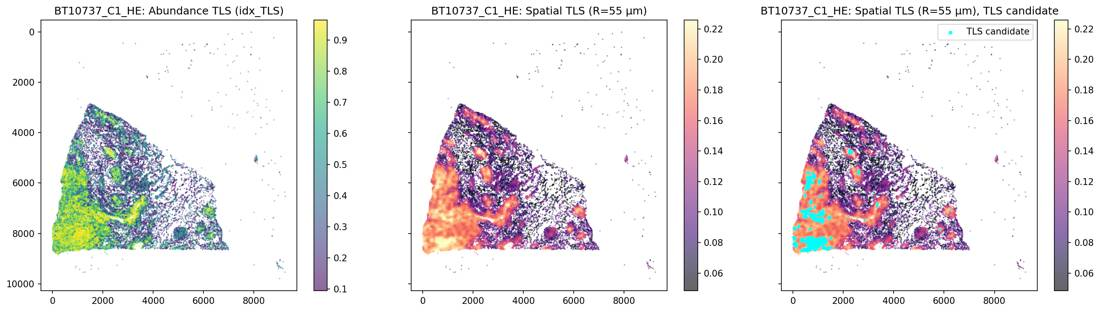

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C1_HE_TLS_abundance_vs_spatial.png


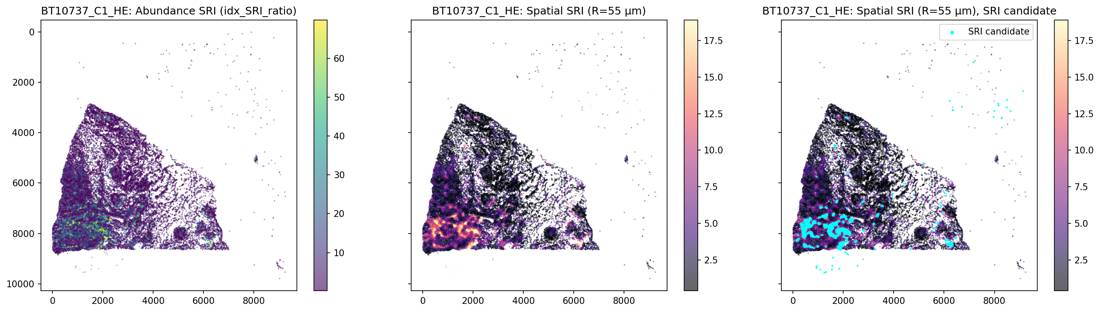

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C1_HE_SRI_abundance_vs_spatial.png


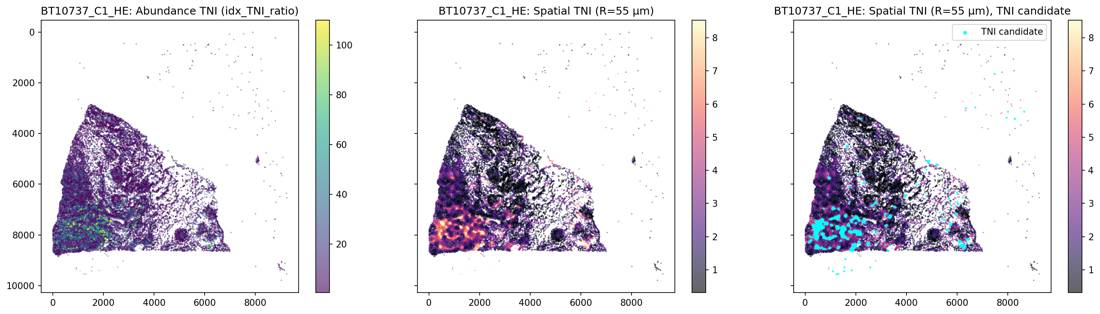

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C1_HE_TNI_abundance_vs_spatial.png


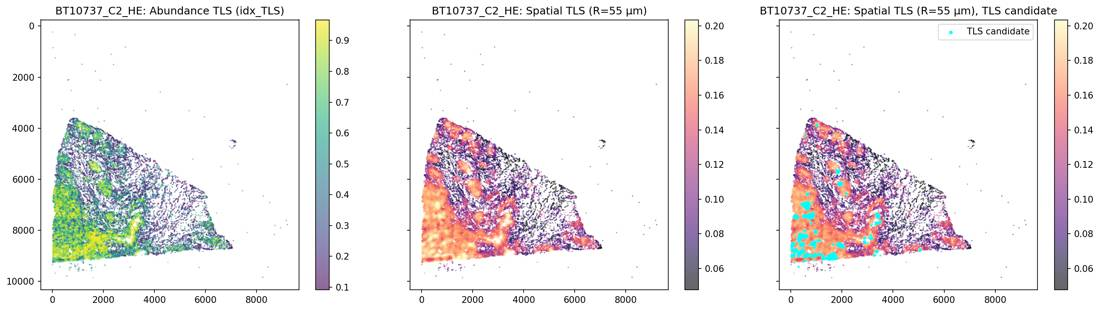

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C2_HE_TLS_abundance_vs_spatial.png


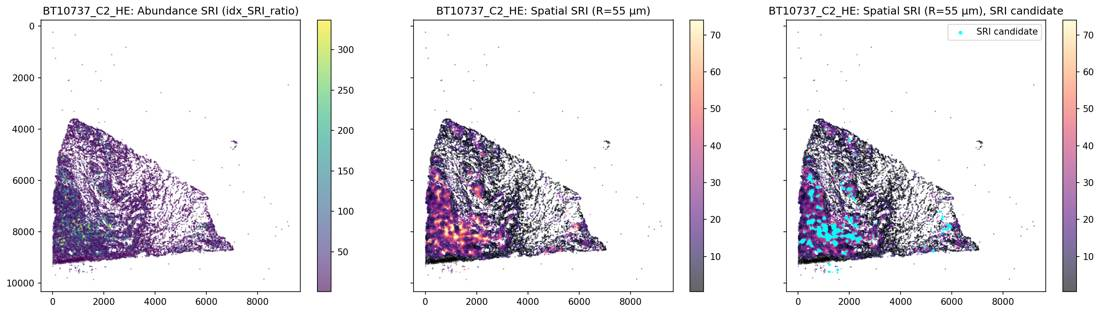

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C2_HE_SRI_abundance_vs_spatial.png


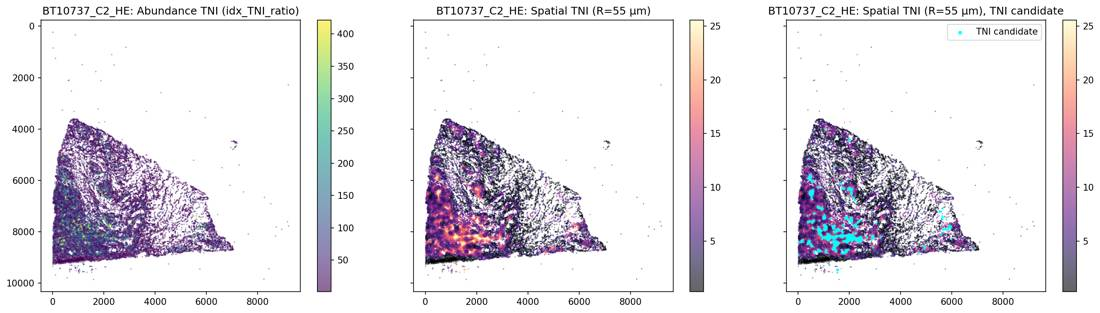

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_C2_HE_TNI_abundance_vs_spatial.png


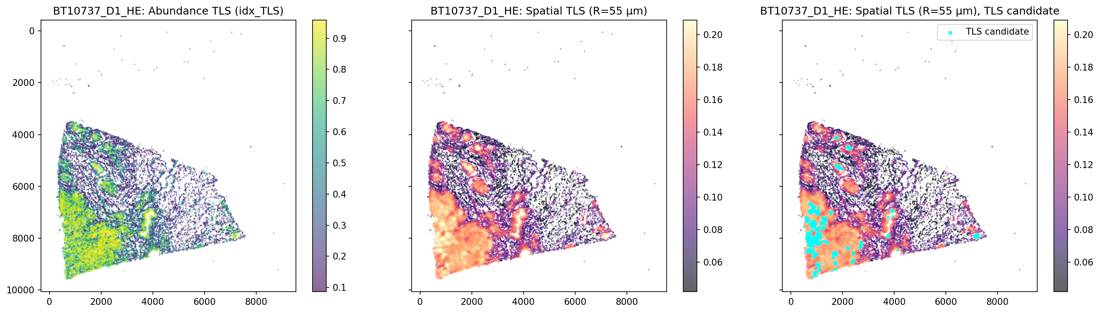

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D1_HE_TLS_abundance_vs_spatial.png


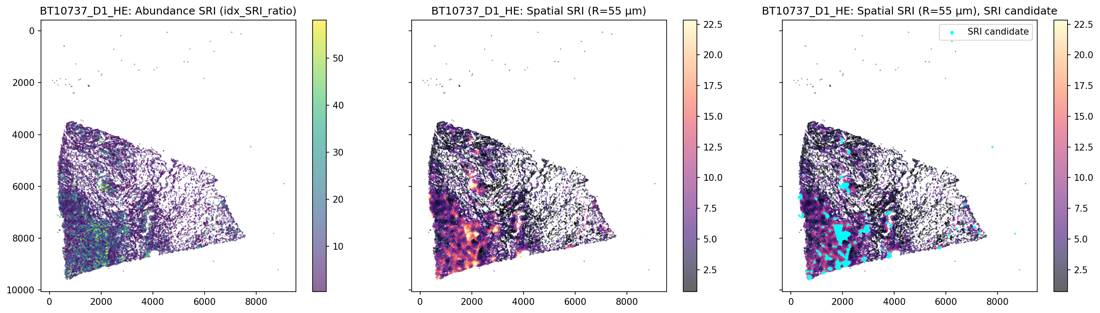

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D1_HE_SRI_abundance_vs_spatial.png


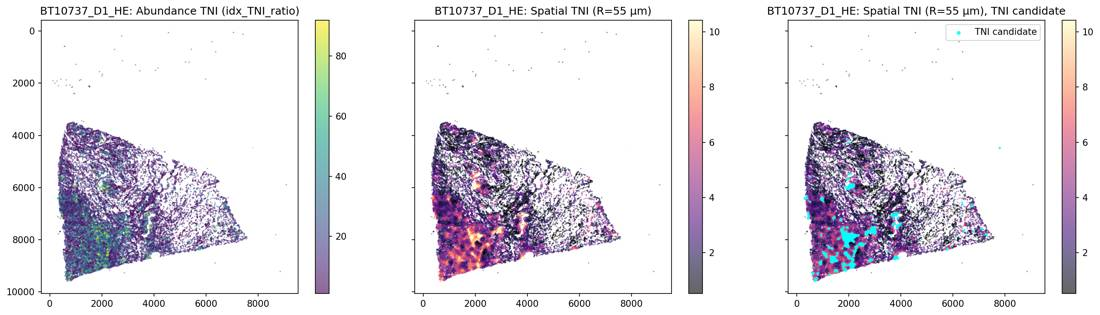

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D1_HE_TNI_abundance_vs_spatial.png


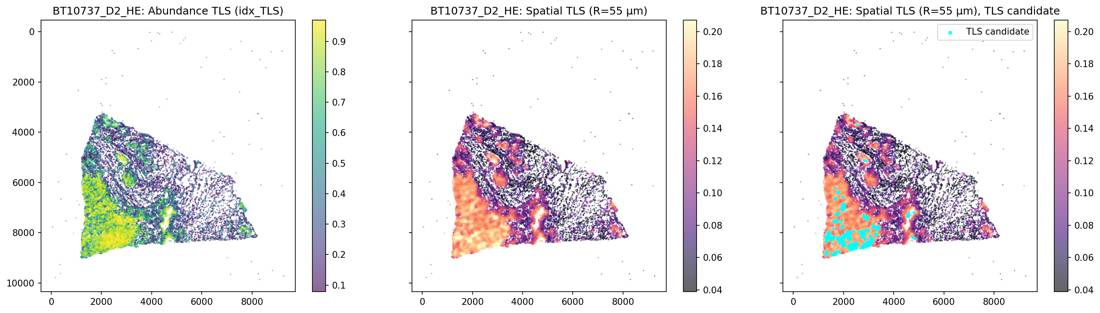

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D2_HE_TLS_abundance_vs_spatial.png


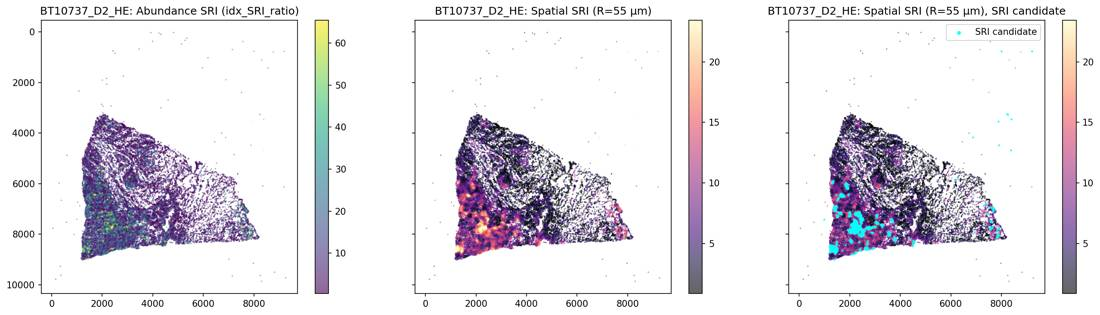

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D2_HE_SRI_abundance_vs_spatial.png


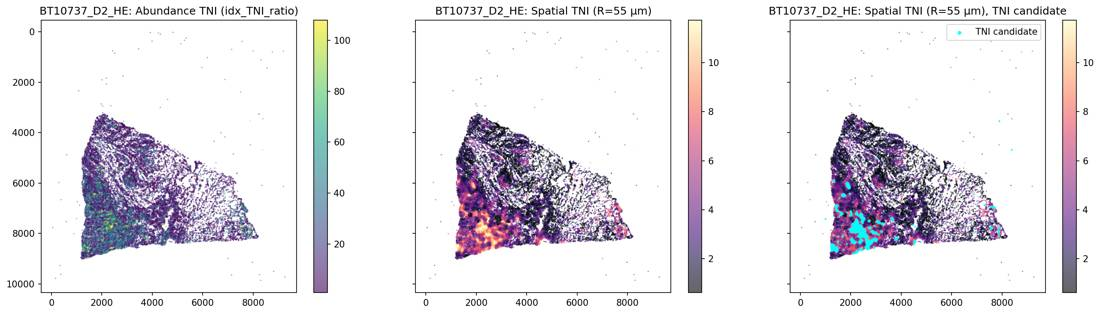

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_D2_HE_TNI_abundance_vs_spatial.png


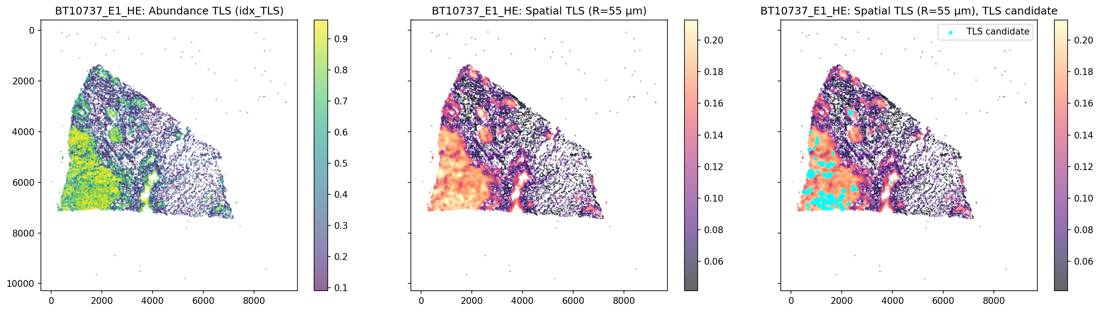

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E1_HE_TLS_abundance_vs_spatial.png


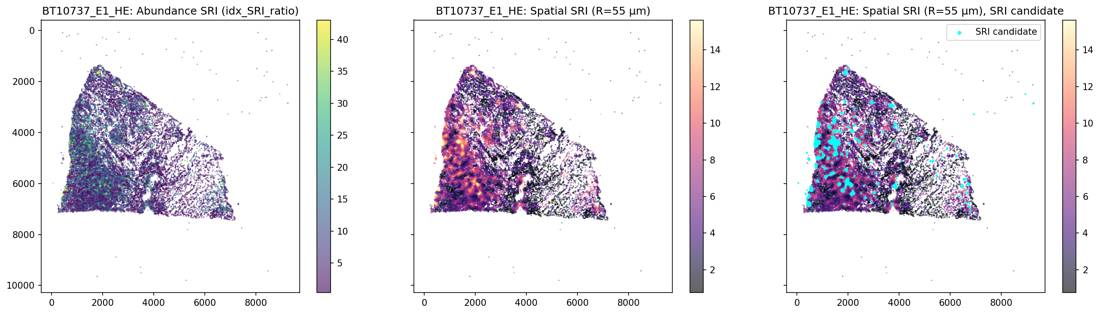

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E1_HE_SRI_abundance_vs_spatial.png


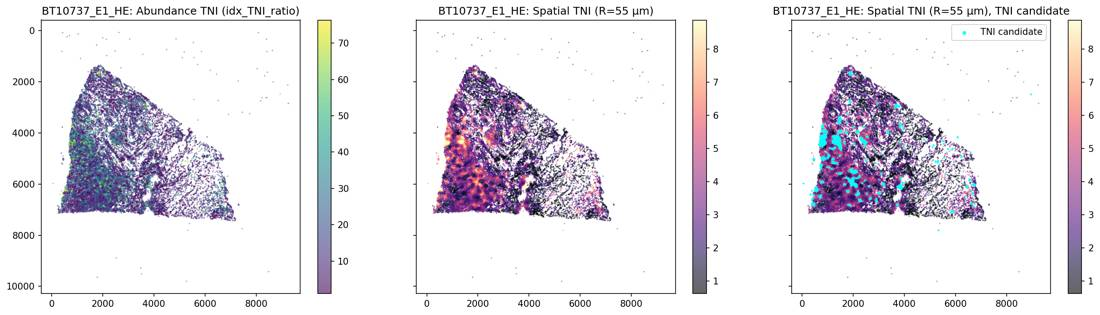

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E1_HE_TNI_abundance_vs_spatial.png


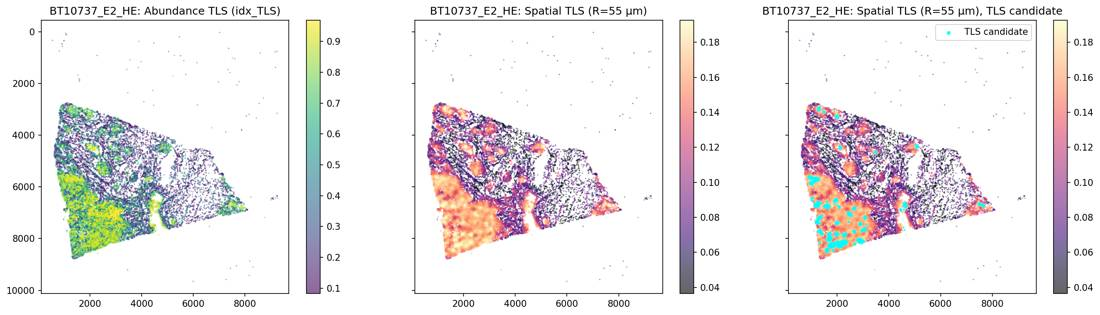

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E2_HE_TLS_abundance_vs_spatial.png


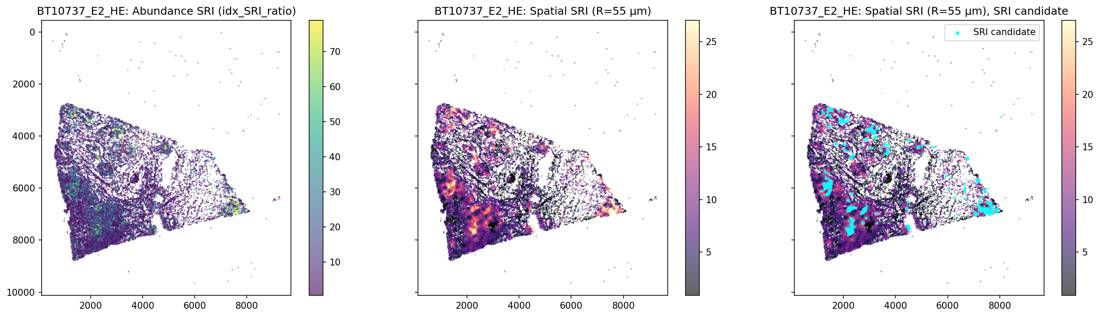

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E2_HE_SRI_abundance_vs_spatial.png


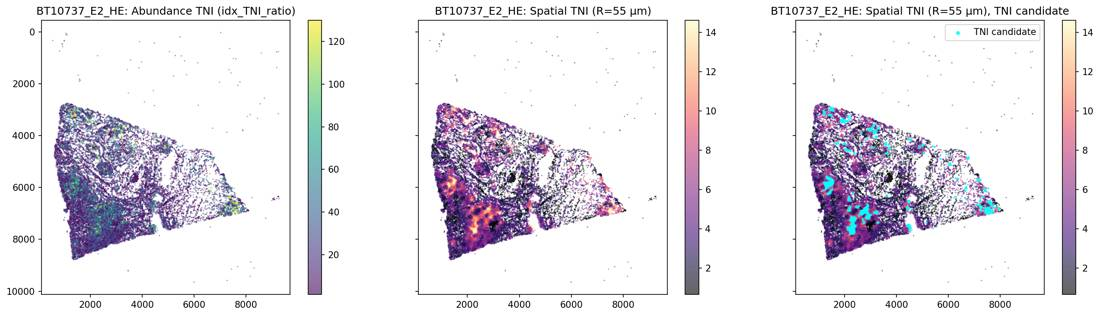

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/BT10737_E2_HE_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
